In [ ]:
!pip install -q opencv-python-headless scikit-image matplotlib numpy scipy

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import feature, color, filters, segmentation as skseg
from skimage.feature import hog
from scipy import ndimage as ndi
from google.colab import files

plt.rcParams['figure.figsize'] = (10, 8)

def show(img, title="", cmap=None):
    plt.figure()
    if cmap is None and img.ndim == 3:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap or 'gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

def show_pair(img1, img2, t1="", t2="", cmap1=None, cmap2=None):
    fig, ax = plt.subplots(1, 2, figsize=(14, 7))
    for a, im, t, cm in zip(ax, [img1, img2], [t1, t2], [cmap1, cmap2]):
        if cm is None and im.ndim == 3:
            a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            a.imshow(im, cmap=cm or 'gray')
        a.set_title(t)
        a.axis('off')
    plt.tight_layout()
    plt.show()


In [ ]:
# --- Option A: upload your own photo ---
uploaded = files.upload()   # choose your tabletop fruit photo
img = None
if uploaded:
    fname = list(uploaded.keys())[0]
    img = cv2.imread(fname)

if img is None:
    print("No image uploaded — will fall back to a synthetic sample in the next cell.")


Saving Screenshot 2026-09-08 213019.png to Screenshot 2026-09-08 213019.png


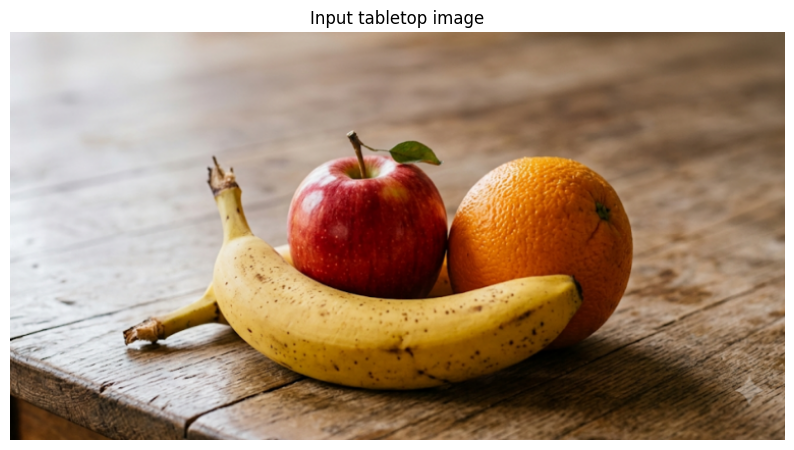

In [ ]:
# --- Option B: fallback synthetic image (only runs if nothing was uploaded) ---
if img is None:
    canvas = np.full((500, 700, 3), (60, 110, 40), dtype=np.uint8)  # table/background
    cv2.circle(canvas, (250, 260), 90, (30, 60, 200), -1)    # "apple" (red, BGR)
    cv2.circle(canvas, (370, 250), 85, (20, 130, 235), -1)   # "orange" (orange, overlapping apple)
    cv2.ellipse(canvas, (520, 300), (110, 55), 20, 0, 360, (30, 210, 235), -1)  # "banana" (yellow)
    noise = np.random.normal(0, 8, canvas.shape).astype(np.int16)
    canvas = np.clip(canvas.astype(np.int16) + noise, 0, 255).astype(np.uint8)
    img = canvas

show(img, "Input tabletop image")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


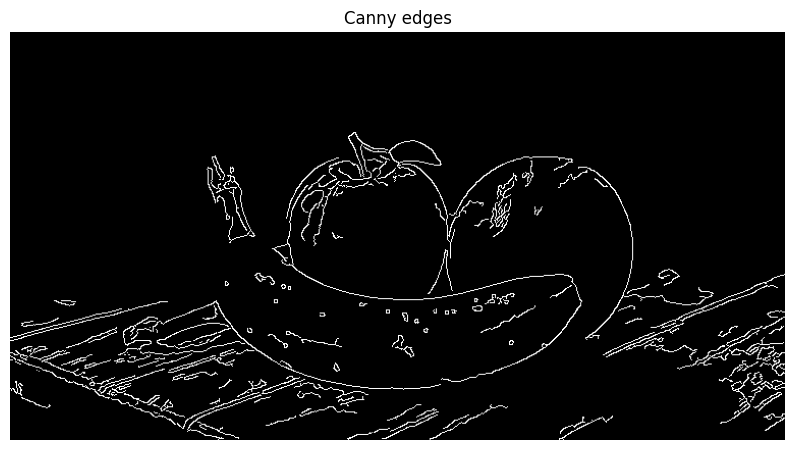

In [ ]:
# Canny edge detection
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
edges = cv2.Canny(blurred, 50, 150)
show(edges, "Canny edges", cmap='gray')


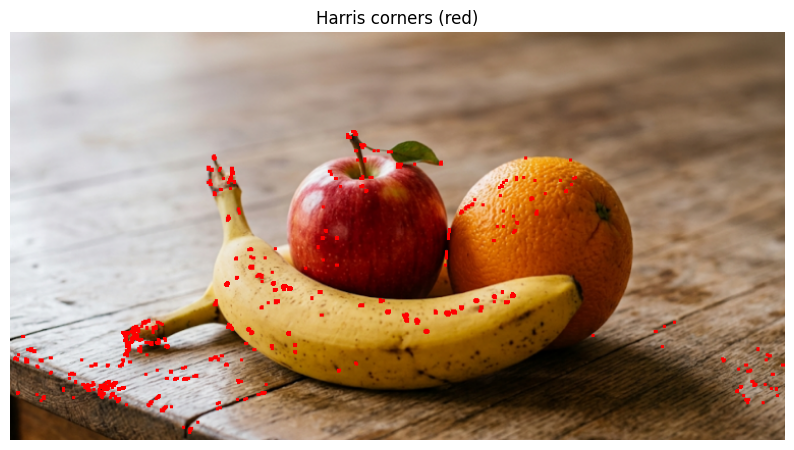

In [ ]:
# Harris corner detection
gray_f = np.float32(gray)
harris = cv2.cornerHarris(gray_f, blockSize=2, ksize=3, k=0.04)
harris = cv2.dilate(harris, None)
harris_vis = img.copy()
harris_vis[harris > 0.01 * harris.max()] = [0, 0, 255]
show(harris_vis, "Harris corners (red)")


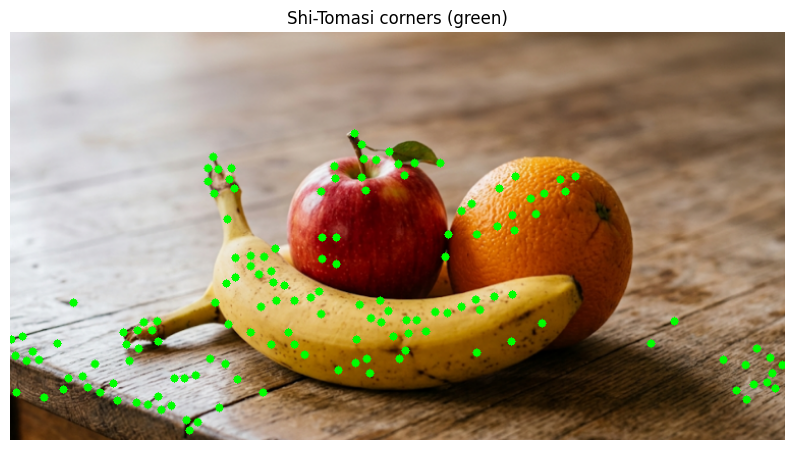

In [ ]:
# Shi-Tomasi corner detection
corners = cv2.goodFeaturesToTrack(gray, maxCorners=150, qualityLevel=0.01, minDistance=10)
shi_vis = img.copy()
if corners is not None:
    for c in corners:
        x, y = c.ravel()
        cv2.circle(shi_vis, (int(x), int(y)), 4, (0, 255, 0), -1)
show(shi_vis, "Shi-Tomasi corners (green)")


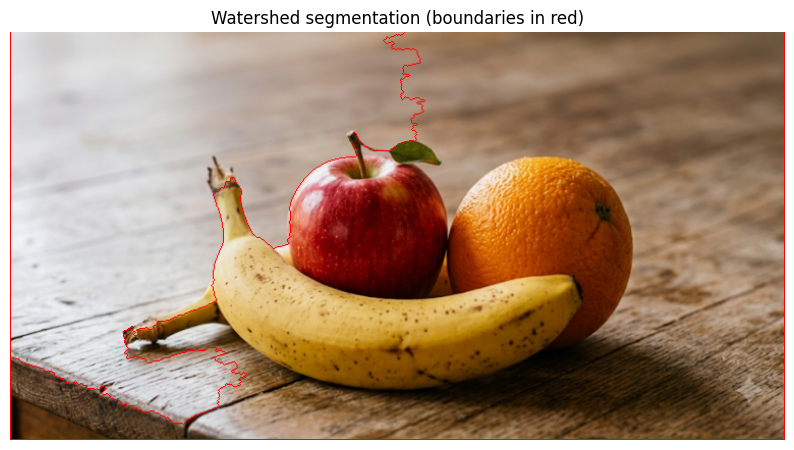

In [ ]:
# --- Technique 1: Watershed segmentation ---
gray_blur = cv2.GaussianBlur(gray, (5, 5), 0)
_, thresh = cv2.threshold(gray_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# noise removal
kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

# sure background
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# sure foreground via distance transform
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist, 0.4 * dist.max(), 255, 0)
sure_fg = np.uint8(sure_fg)

unknown = cv2.subtract(sure_bg, sure_fg)

# marker labelling
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

markers_ws = cv2.watershed(img.copy(), markers)
watershed_vis = img.copy()
watershed_vis[markers_ws == -1] = [0, 0, 255]  # boundaries in red

show(watershed_vis, "Watershed segmentation (boundaries in red)")


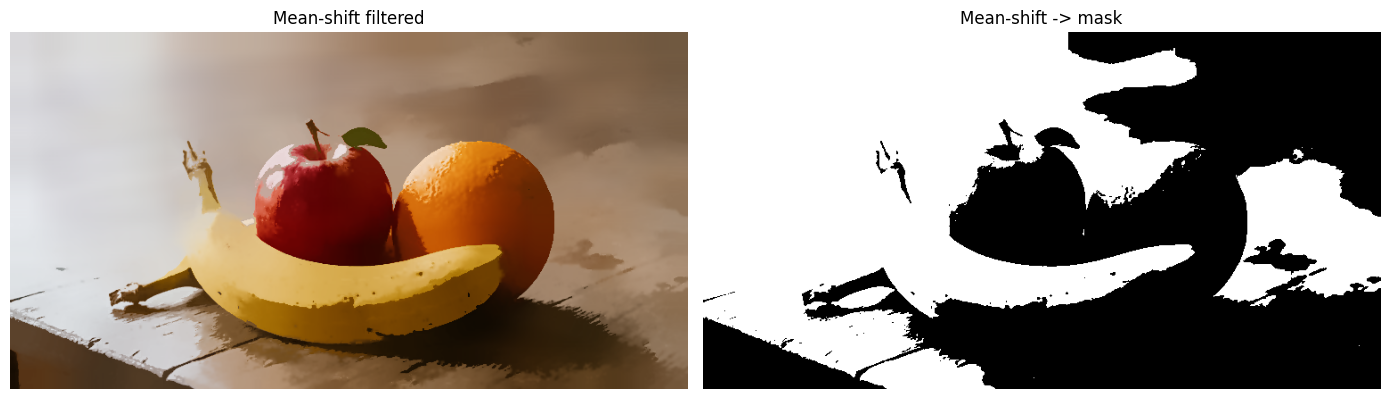

In [ ]:
# --- Technique 2: Mean-Shift segmentation ---
shifted = cv2.pyrMeanShiftFiltering(img, sp=21, sr=51)
shifted_gray = cv2.cvtColor(shifted, cv2.COLOR_BGR2GRAY)
_, ms_thresh = cv2.threshold(shifted_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
n_labels_ms, labels_ms = cv2.connectedComponents(ms_thresh)

show_pair(shifted, cv2.cvtColor(ms_thresh, cv2.COLOR_GRAY2BGR),
          "Mean-shift filtered", "Mean-shift -> mask")


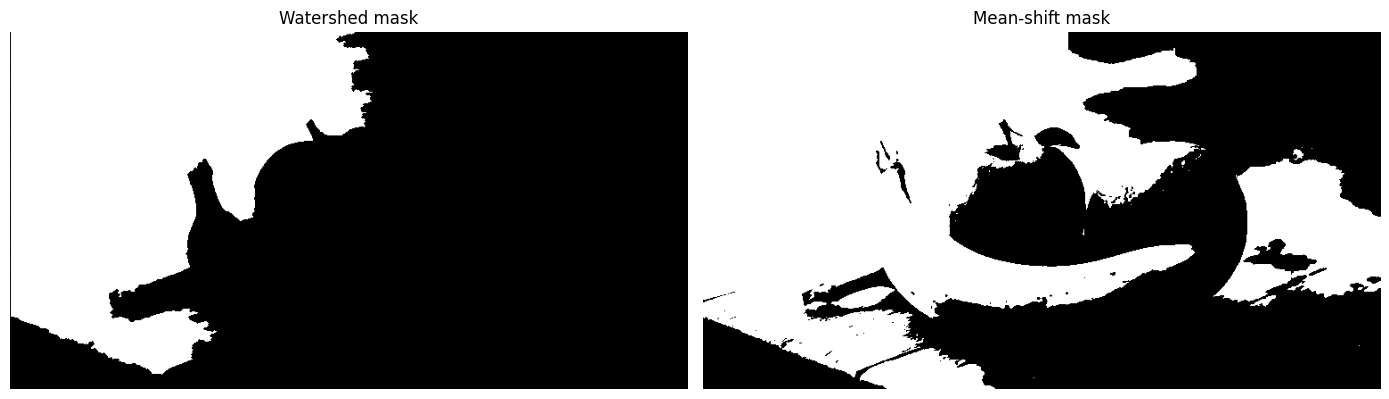

In [ ]:
# --- Side-by-side comparison of the two segmentation masks ---
ws_mask = np.uint8(markers_ws > 1) * 255
show_pair(ws_mask, ms_thresh, "Watershed mask", "Mean-shift mask")


Detected candidate boxes (x, y, w, h): [(1, 1, 406, 384)]


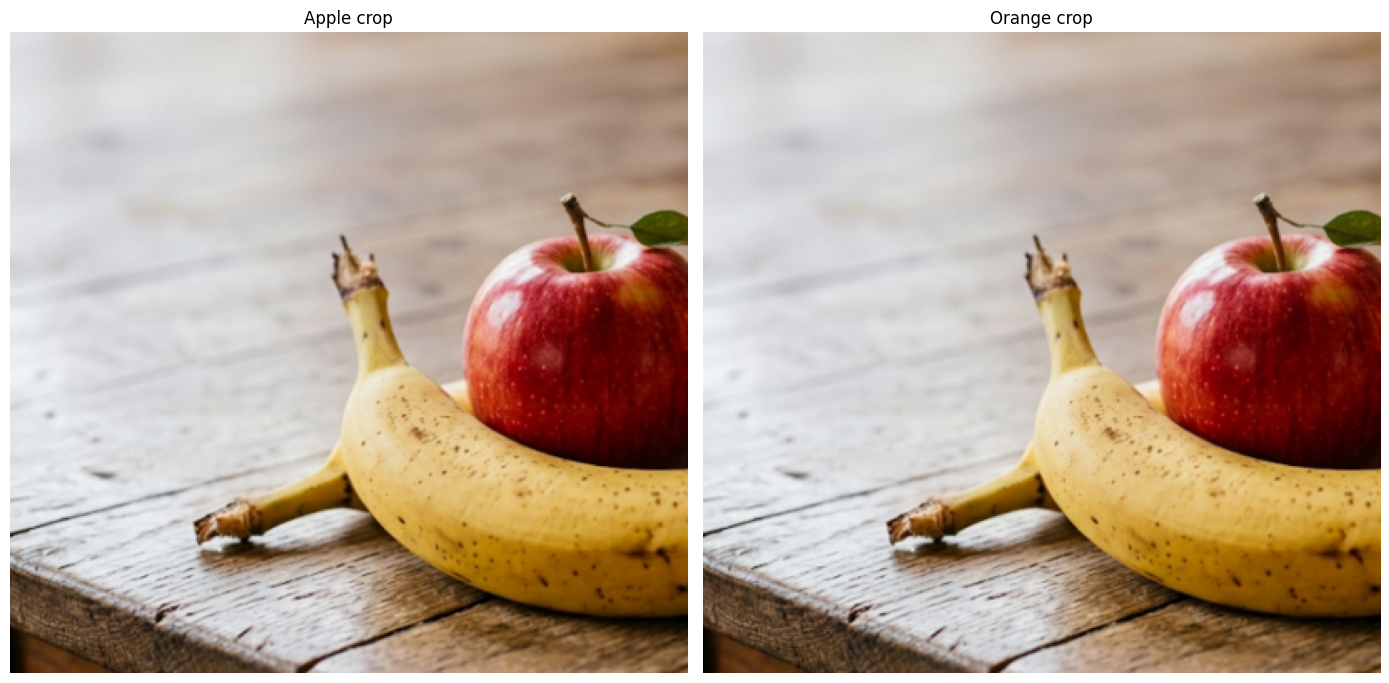

In [ ]:
# Get bounding boxes for connected components (adjust selection to match your actual apple/orange)
contours, _ = cv2.findContours(ws_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)

boxes = [cv2.boundingRect(c) for c in contours[:3]]
print("Detected candidate boxes (x, y, w, h):", boxes)

# TODO: after inspecting `boxes` / the watershed mask above, set these indices
# to whichever boxes actually correspond to your apple and your orange.
apple_box = boxes[0]
orange_box = boxes[1] if len(boxes) > 1 else boxes[0]

def crop(box, image):
    x, y, w, h = box
    return image[y:y+h, x:x+w]

apple_crop = crop(apple_box, img)
orange_crop = crop(orange_box, img)
show_pair(apple_crop, orange_crop, "Apple crop", "Orange crop")


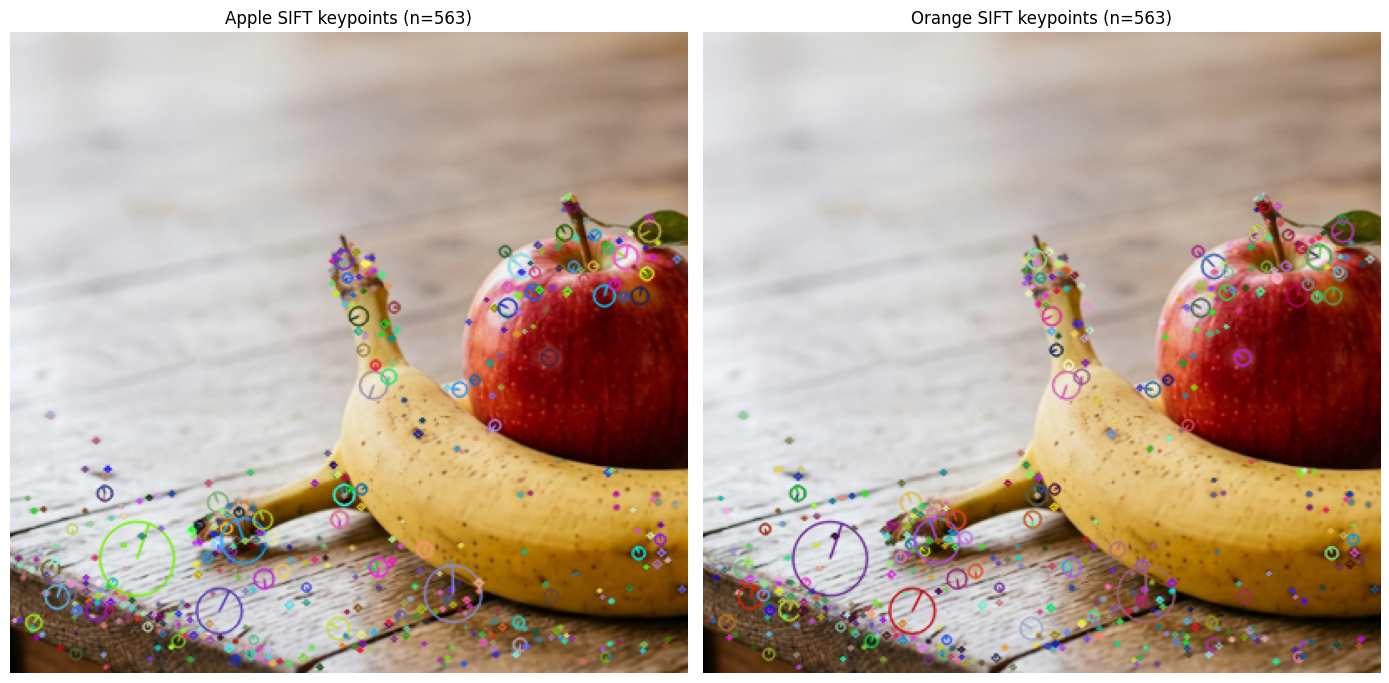

In [ ]:
# SIFT keypoints + descriptors
sift = cv2.SIFT_create()

apple_gray = cv2.cvtColor(apple_crop, cv2.COLOR_BGR2GRAY)
orange_gray = cv2.cvtColor(orange_crop, cv2.COLOR_BGR2GRAY)

kp_apple, des_apple = sift.detectAndCompute(apple_gray, None)
kp_orange, des_orange = sift.detectAndCompute(orange_gray, None)

apple_sift_vis = cv2.drawKeypoints(apple_crop, kp_apple, None,
                                    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
orange_sift_vis = cv2.drawKeypoints(orange_crop, kp_orange, None,
                                     flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

show_pair(apple_sift_vis, orange_sift_vis,
          f"Apple SIFT keypoints (n={len(kp_apple)})",
          f"Orange SIFT keypoints (n={len(kp_orange)})")


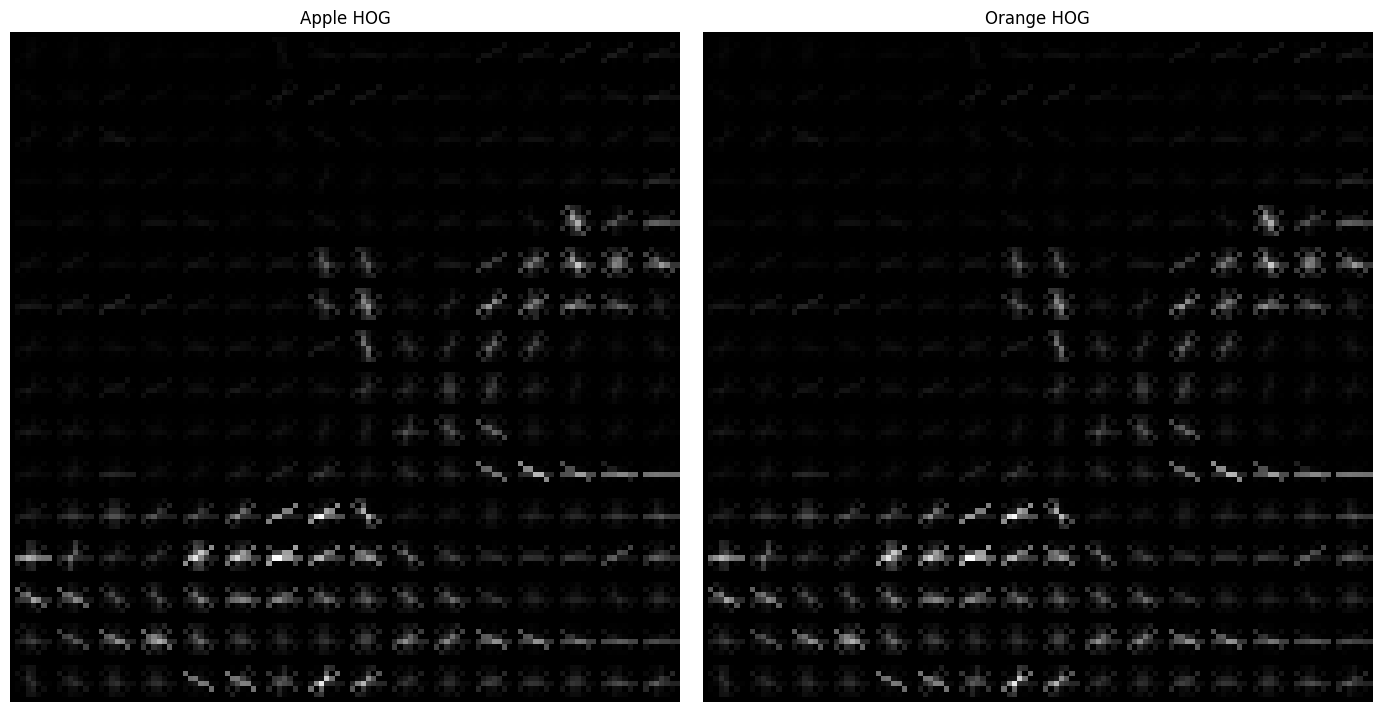

In [ ]:
# HOG descriptor (alternative / complementary to SIFT)
apple_resized = cv2.resize(apple_gray, (128, 128))
orange_resized = cv2.resize(orange_gray, (128, 128))

hog_feat_apple, hog_img_apple = hog(apple_resized, orientations=9, pixels_per_cell=(8, 8),
                                     cells_per_block=(2, 2), visualize=True)
hog_feat_orange, hog_img_orange = hog(orange_resized, orientations=9, pixels_per_cell=(8, 8),
                                       cells_per_block=(2, 2), visualize=True)

show_pair(hog_img_apple, hog_img_orange, "Apple HOG", "Orange HOG")


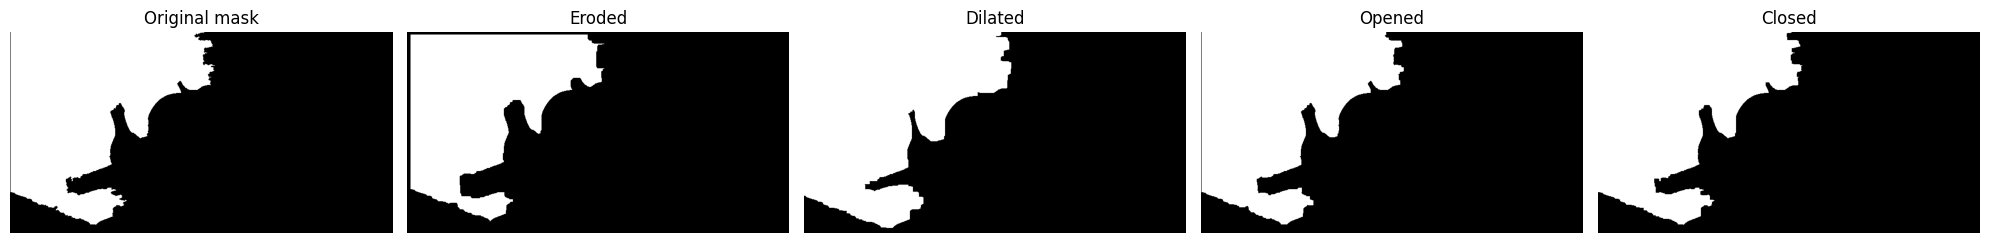

In [ ]:
# Simulate/inspect a case where two touching fruits were merged into one blob
merged_mask = ws_mask.copy()  # swap for a mask region where you can see two fruits fused together

kernel = np.ones((7, 7), np.uint8)

eroded   = cv2.erode(merged_mask, kernel, iterations=2)
dilated  = cv2.dilate(merged_mask, kernel, iterations=2)
opened   = cv2.morphologyEx(merged_mask, cv2.MORPH_OPEN, kernel, iterations=1)
closed   = cv2.morphologyEx(merged_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

fig, ax = plt.subplots(1, 5, figsize=(20, 5))
for a, im, t in zip(ax, [merged_mask, eroded, dilated, opened, closed],
                     ["Original mask", "Eroded", "Dilated", "Opened", "Closed"]):
    a.imshow(im, cmap='gray')
    a.set_title(t)
    a.axis('off')
plt.tight_layout()
plt.show()


Connected components before erosion: 1
Connected components after erosion:  1


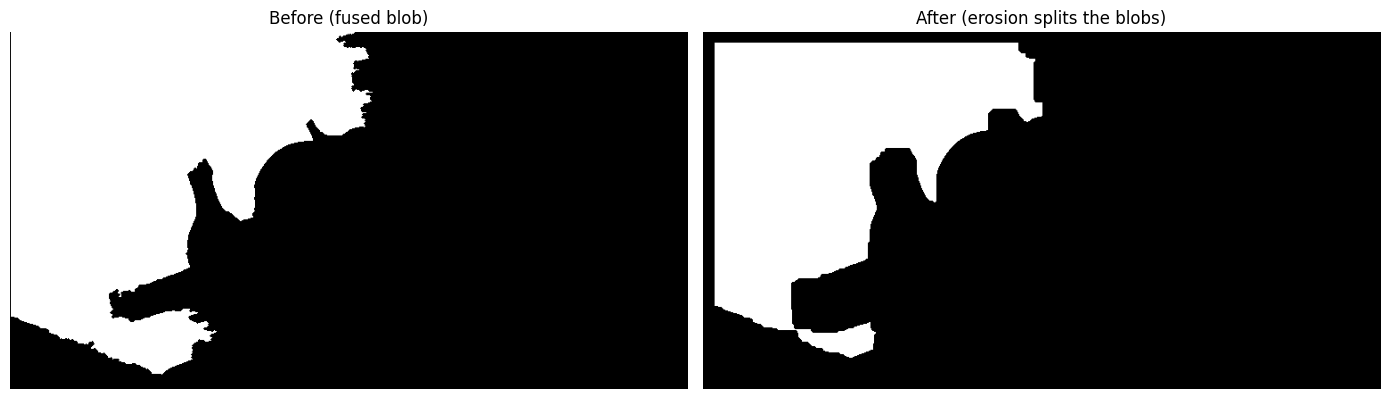

In [ ]:
# Practical fix for two touching fruits fused into one blob:
# erode to shrink the neck connecting them until it separates, then re-label
separated = cv2.erode(merged_mask, kernel, iterations=4)
n_labels_before, _ = cv2.connectedComponents(merged_mask)
n_labels_after, _ = cv2.connectedComponents(separated)
print(f"Connected components before erosion: {n_labels_before - 1}")
print(f"Connected components after erosion:  {n_labels_after - 1}")

show_pair(merged_mask, separated, "Before (fused blob)", "After (erosion splits the blobs)")
